# 18c · Anomaly scores need a reference population

## The engineering question
Is a request unusual relative to the reference corpus, and what errors does a chosen threshold create?

**Learning outcomes:** construct a normal-only reference set; score distance to nearby examples; choose a threshold on development data; report held-out false positives/negatives; avoid interpreting unusualness as wrongdoing.

The reference population is the twelve support sentences. Anomaly score is one minus mean cosine similarity to the three closest reference points. Development and test fixtures contain normal paraphrases and deliberately unrelated requests. A threshold is selected on development F1 with a conservative tie-break, then frozen. This detects topic novelty in an artificial workload; it does not detect maliciousness, fraud, or a system outage.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("18c", "B", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


In [2]:
import json

fixtures = json.loads((root() / "datasets/applications.json").read_text())

,split,text,expected_anomaly,score,predicted_anomaly
0,development,The payment receipt lists the wrong amount,False,0.558419,False
1,development,Router connection drops intermittently,False,0.452114,False
2,development,Write a dramatic monologue for a space pirate,True,0.944173,True
3,development,Tell me the recipe for chocolate cake,True,0.911184,True
4,test,I forgot my account password,False,0.414451,False
5,test,Our subscription invoice is duplicated,False,0.444746,False
6,test,Gateway cannot connect over Ethernet,False,0.532512,False
7,test,Find a hotel room near the beach,True,0.899944,False
8,test,Derive the orbit of a comet,True,0.885272,False
9,test,Compose a sonnet about wildflowers,True,0.928555,True


Frozen threshold: 0.9 Test metrics: {'tp': 1, 'fp': 0, 'fn': 2, 'tn': 3, 'precision': 1.0, 'recall': 0.3333333333333333, 'f1': 0.5}


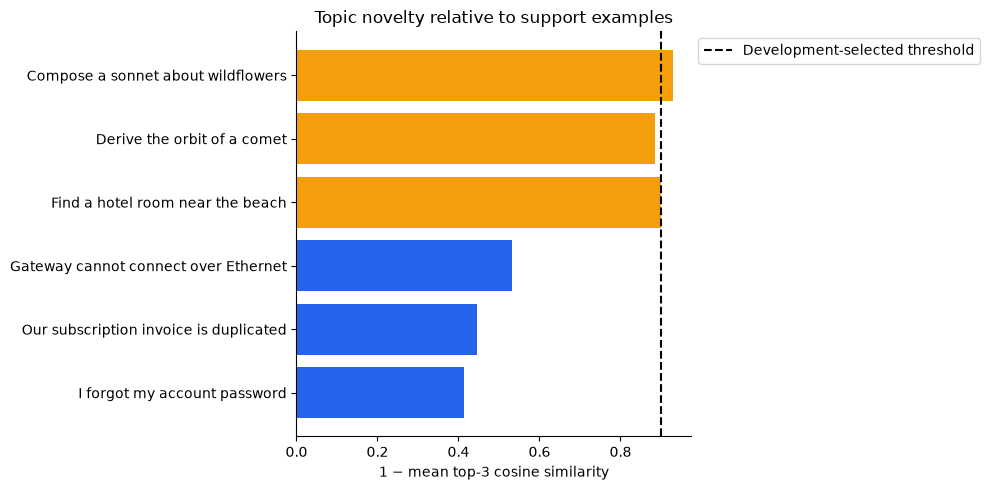

In [3]:
from vector_masterclass.models import embed
from vector_masterclass.applications import binary_metrics

reference_texts = [t for t, l in fixtures["classification"]["train"]]
reference = embed(reference_texts)


def scores(texts):
    similarities = embed(texts) @ reference.T
    return 1 - np.sort(similarities, axis=1)[:, -3:].mean(axis=1)


cfg = fixtures["anomaly"]
dev_scores = scores([t for t, l in cfg["development"]])
dev_labels = [l for t, l in cfg["development"]]
sweep = pd.DataFrame(
    [
        {"threshold": float(th), **binary_metrics(dev_labels, dev_scores > th)}
        for th in np.linspace(0, 1, 51)
    ]
)
chosen = float(
    sweep.sort_values(["f1", "precision", "threshold"], ascending=[False, False, False])
    .iloc[0]
    .threshold
)
rows = []
for split in ["development", "test"]:
    for (text, expected), score in zip(cfg[split], scores([t for t, l in cfg[split]])):
        rows.append(
            {
                "split": split,
                "text": text,
                "expected_anomaly": expected,
                "score": float(score),
                "predicted_anomaly": bool(score > chosen),
            }
        )
results = lesson.table(pd.DataFrame(rows))
lesson.table(sweep, "development-thresholds")
test = results[results.split.eq("test")]
metrics = binary_metrics(test.expected_anomaly, test.predicted_anomaly)
display(results)
print("Frozen threshold:", chosen, "Test metrics:", metrics)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(
    range(len(test)),
    test.score,
    color=["#f59e0b" if value else "#2563eb" for value in test.expected_anomaly],
)
ax.axvline(chosen, color="black", linestyle="--", label="Development-selected threshold")
ax.set(
    yticks=range(len(test)),
    yticklabels=[t[:46] for t in test.text],
    xlabel="1 − mean top-3 cosine similarity",
    title="Topic novelty relative to support examples",
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
An unusual but legitimate request is a false positive if the goal is support triage. A novel failure can sound similar to routine network messages and become a false negative. The reference distribution and labeling objective define what the score means. Thresholds calibrated on a few synthetic outliers do not transfer automatically to real traffic.

**Exercise:** add a legitimate new product line to the test set without adding it to the reference set. Measure the false-positive change, then propose a reviewed reference update. Explain why adding every flagged request to the reference can hide persistent anomalies and why a high anomaly score is not evidence of wrongdoing.

Production monitoring needs base rates, false-alert cost, time/source splits, drift, human review, and retraining/invalidation policy. Keep anomaly detection separate from authorization or punitive actions.

In [ ]:
manifest = lesson.finish(
    {
        "normal_reference_only": len(reference) == 12,
        "both_test_classes": set(test.expected_anomaly) == {False, True},
        "held_out_count": len(test) == 6,
        "finite_scores": bool(np.isfinite(results.score).all()),
        "no_reference_test_overlap": not set(reference_texts) & set(test.text),
    },
    observations={
        "frozen_threshold": chosen,
        "test_metrics": metrics,
        "score_meaning": "topic novelty, not maliciousness",
        "threshold_split": "development",
    },
)

## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.